# Heart-rate estimation — spectral baseline + gradient boosting

**Goal:** Estimate heart rate from wrist PPG, check the errors against ECG-derived reference labels, and see whether a small trained model improves on the frequency-based baseline.

**Plan:** Load signals → spectral baseline → time-series features → chronological split → compare models/features → evaluate on untouched test data.

The ECG-derived reference is **never included among the prediction features**. Plots can show a short interval; baseline calculations and ML feature extraction cover each participant's entire available recording.

## 1. Load the subjects

Use the same subject IDs and dataset folder as in notebook 01. You can select **one or two subjects**; the code handles both. The times below are seconds from each participant's own recording start, so the same time does **not** guarantee the same activity for different subjects.

*Security: load pickle files only from the trusted dataset download; Python pickle can execute code during loading.*

In [1]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

SUBJECTS = ["S1", "S4"]
# SUBJECTS = ["S1"]
DATA_FOLDER = Path("../Data/PPG_FieldStudy")

timeline = {"NO:_ACTIVITY1":	0,
 "BASELINE":	90,
 "NO_ACTIVITY2":	791,
 "STAIRS":	837,
 "NO_ACTIVITY3":	1125,
 "SOCCER":	1210,
 "NO_ACTIVITY4":	1556,
 "CYCLING":	1918,
 "NO_ACTIVITY5":	2331,
 "DRIVING":	2935,
 "NO_ACTIVITY6":	3825,
 "LUNCH":	4595,
 "WALKING":	6951,
 "NO_ACTIVITY7":	7706,
 "WORKING":	7791,
 "NO_ACTIVITY8":	8981,
 "CLEAN_BASELINE":	9077,
 "NO_ACTIVITY9":	9198}


GRAPH_START = timeline["DRIVING"] + 285
GRAPH_DURATION = 90


PPG_HZ = 64
ACC_HZ = 32
WINDOW = 8         # 8-second windows
STEP = 2           # Move forward 2 seconds each time
MIN_HZ = 0.65      # 39 BPM
MAX_HZ = 3.5       # 210 BPM

In [2]:
recordings = {}

for subject in SUBJECTS:
    file = DATA_FOLDER / subject / f"{subject}.pkl"
    with open(file, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    recordings[subject] = {
        "ppg": np.asarray(data["signal"]["wrist"]["BVP"]).flatten(),
        "reference_hr": np.asarray(data["label"]).flatten(),
        "acc": np.asarray(data["signal"]["wrist"]["ACC"])
    }

    print(f"{subject}: {len(recordings[subject]['ppg']):,} PPG samples, "
          f"{len(recordings[subject]['reference_hr']):,} reference labels")

S1: 589,568 PPG samples, 4,603 reference labels
S4: 585,600 PPG samples, 4,572 reference labels


## 2. Spectral baseline

For each 8-second PPG window (2-second stride), estimate heart rate from the strongest spectral peak between 0.65 and 3.5 Hz. Multiply that frequency by 60 to obtain BPM.

Both raw and filtered estimates use **the same Welch spectrum** so the comparison isolates the filtering step. Zero-padding (`nfft=4096`) smooths the sampled spectrum but cannot add information to an 8-second recording.

In [3]:
def estimate_hr(ppg_window):
    if not np.isfinite(ppg_window).all():
        return np.nan

    freq, power = signal.welch(
        ppg_window, fs=PPG_HZ, nperseg=len(ppg_window), nfft=4096
    )
    pulse_range = (freq >= MIN_HZ) & (freq <= MAX_HZ)
    peak = freq[pulse_range][np.argmax(power[pulse_range])]
    return peak * 60

## 3. Filter and estimate across the entire recording

Apply a 0.7–3.5 Hz Butterworth bandpass filter to each full PPG recording, then estimate BPM in overlapping 8-second windows. **Reference HR is used only when storing the matching target for evaluation**, not inside `estimate_hr`.

`filtfilt` is an **offline, non-causal** filter: it uses neighboring samples in both directions. This prototype is for offline analysis, not live streaming.

In [4]:
results = {}

# Butterworth bandpass filter (0.7–3.5 Hz)
sos = signal.butter(
    3,
    [0.7, 3.5],
    btype="bandpass",
    fs=PPG_HZ,
    output="sos"
)

for subject in SUBJECTS:
    ppg = recordings[subject]["ppg"]
    reference_hr = recordings[subject]["reference_hr"]

    last_index = min(
        len(reference_hr) - 1,
        (len(ppg) - WINDOW * PPG_HZ) // (STEP * PPG_HZ)
    )

    assert last_index >= 0, f"{subject}: recording is too short."
    assert np.isfinite(ppg).all(), f"{subject}: PPG contains missing/non-finite values."

    filtered_ppg = signal.sosfiltfilt(sos, ppg)
    recordings[subject]["filtered_ppg"] = filtered_ppg

    rows = []
    for i in range(last_index + 1):
        start = i * STEP * PPG_HZ
        end = start + WINDOW * PPG_HZ

        raw_bpm = estimate_hr(ppg[start:end])
        filtered_bpm = estimate_hr(filtered_ppg[start:end])

        rows.append({
            "Time (s)": i * STEP + WINDOW / 2,
            "Raw estimate (BPM)": raw_bpm,
            "Filtered estimate (BPM)": filtered_bpm,
            "Reference HR (BPM)": reference_hr[i]
        })

    results[subject] = pd.DataFrame(rows)
    print(f"{subject}: {len(results[subject])} complete windows analyzed")

display(results[SUBJECTS[0]].head())

S1: 4603 complete windows analyzed
S4: 4572 complete windows analyzed


,Time (s),Raw estimate (BPM),Filtered estimate (BPM),Reference HR (BPM)
0,4.0,44.0625,45.0000,49.611369
1,6.0,43.1250,46.8750,50.323992
2,8.0,53.4375,53.4375,52.708336
3,10.0,52.5000,52.5000,55.640794
4,12.0,53.4375,52.5000,57.658406


## 4. Inspect a short signal segment

`GRAPH_START` and `GRAPH_DURATION` affect the figures only, **not** the estimation or evaluation data.

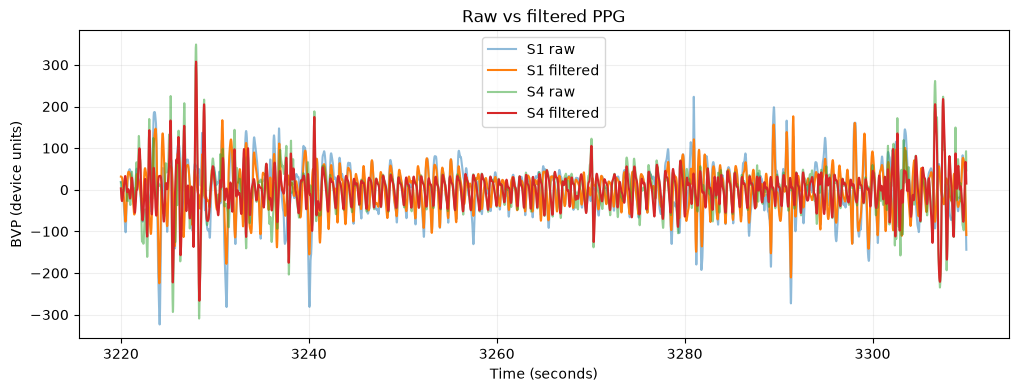

In [5]:
plt.figure(figsize=(12, 4))

for subject in SUBJECTS:
    ppg = recordings[subject]["ppg"]
    filtered_ppg = recordings[subject]["filtered_ppg"]

    start = int(GRAPH_START * PPG_HZ)
    end = int((GRAPH_START + GRAPH_DURATION) * PPG_HZ)

    assert end <= len(ppg), f"{subject}: graph segment exceeds recording."
    time = np.arange(start, end) / PPG_HZ

    plt.plot(time, ppg[start:end], alpha=0.5, label=f"{subject} raw")
    plt.plot(time, filtered_ppg[start:end], label=f"{subject} filtered")

plt.title("Raw vs filtered PPG")
plt.xlabel("Time (seconds)")
plt.ylabel("BVP (device units)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 5. Inspect one 8-second frequency spectrum

A dominant spectral peak is a pulse *candidate*; movement may produce a stronger competing peak.

S1: estimated HR = 69.4 BPM
S4: estimated HR = 60.0 BPM


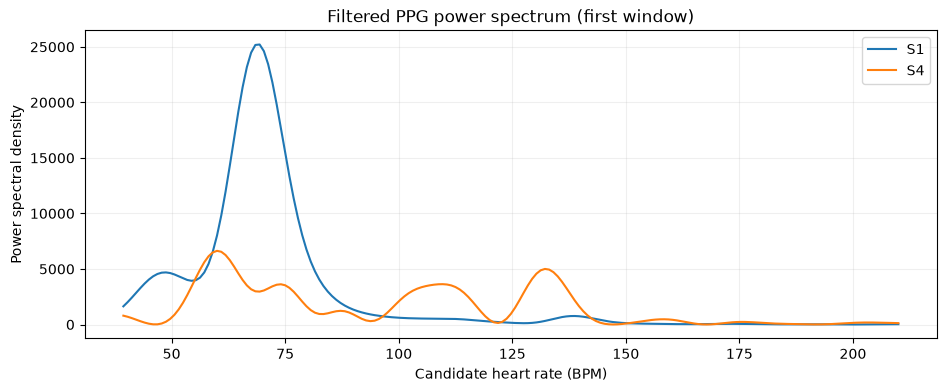

In [6]:
plt.figure(figsize=(11, 4))

for subject in SUBJECTS:
    ppg = recordings[subject]["filtered_ppg"]
    start = int(GRAPH_START * PPG_HZ)
    window = ppg[start:start + WINDOW * PPG_HZ]

    freq, power = signal.welch(window, fs=PPG_HZ,
                               nperseg=len(window), nfft=4096)
    pulse_range = (freq >= MIN_HZ) & (freq <= MAX_HZ)

    plt.plot(freq[pulse_range] * 60, power[pulse_range], label=subject)
    print(f"{subject}: estimated HR = {estimate_hr(window):.1f} BPM")

plt.title("Filtered PPG power spectrum (first window)")
plt.xlabel("Candidate heart rate (BPM)")
plt.ylabel("Power spectral density")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 6. Compare spectral estimates against the reference

The chart shows only the selected interval; the error summary below uses each participant's **full recording**.

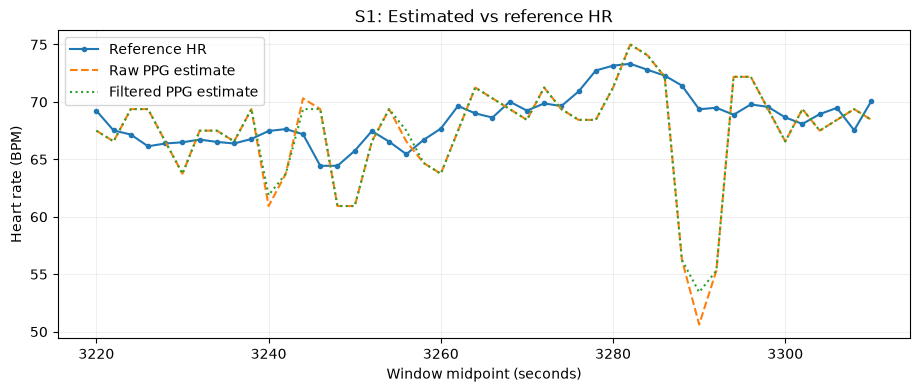

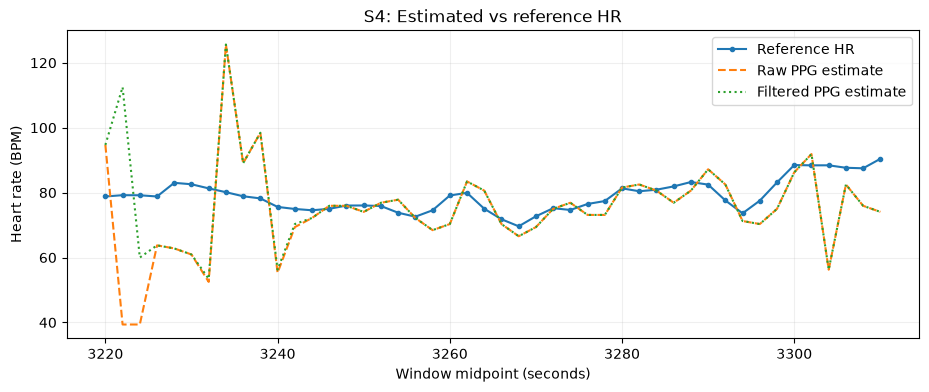

In [7]:
for subject in SUBJECTS:
    df = results[subject]

    # Filter only what is displayed, not the calculated results
    df = df[
        (df["Time (s)"] >= GRAPH_START) &
        (df["Time (s)"] <= GRAPH_START + GRAPH_DURATION)
    ]

    plt.figure(figsize=(11, 4))
    plt.plot(df["Time (s)"], df["Reference HR (BPM)"], label="Reference HR", marker=".")
    plt.plot(df["Time (s)"], df["Raw estimate (BPM)"], label="Raw PPG estimate", linestyle="--")
    plt.plot(df["Time (s)"], df["Filtered estimate (BPM)"], label="Filtered PPG estimate", linestyle=":")

    plt.title(f"{subject}: Estimated vs reference HR")
    plt.xlabel("Window midpoint (seconds)")
    plt.ylabel("Heart rate (BPM)")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

## 7. Full-recording spectral baseline errors

- **MAE:** average absolute error (BPM); lower is better.
- **Mean error:** average signed error; positive means overestimation.

Windows overlap heavily, so their errors are not independent. These results are **not** unseen-subject performance.

In [8]:
summary = []

for subject in SUBJECTS:
    df = results[subject]

    for method in ["Raw estimate (BPM)", "Filtered estimate (BPM)"]:
        error = df[method] - df["Reference HR (BPM)"]
        error = error.dropna()

        summary.append({
            "Subject": subject,
            "Method": method.replace(" estimate (BPM)", " PPG"),
            "Windows": len(error),
            "MAE (BPM)": error.abs().mean(),
            "Mean error (BPM)": error.mean()
        })

summary = pd.DataFrame(summary)
display(summary.round(2))

,Subject,Method,Windows,MAE (BPM),Mean error (BPM)
0,S1,Raw PPG,4603,12.00,-6.31
1,S1,Filtered PPG,4603,10.05,-2.77
2,S4,Raw PPG,4572,20.26,-16.36
3,S4,Filtered PPG,4572,15.91,-10.99


## 8. Train a small model using PPG and acceleration features

We extract features from each 8-second segment, rather than treating 64 Hz PPG samples as independent rows. The model can learn nonlinear relationships between spectral properties, wrist movement, and reference heart rate. Reference HR is stored as the training **target only**.

In [9]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

feature_rows = []

for subject in SUBJECTS:
    ppg = recordings[subject]["ppg"]
    filtered = recordings[subject]["filtered_ppg"]
    acc = recordings[subject]["acc"]
    reference_hr = recordings[subject]["reference_hr"]

    n_windows = min(
        len(reference_hr),
        (len(ppg) - WINDOW * PPG_HZ) // (STEP * PPG_HZ) + 1,
        (len(acc) - WINDOW * ACC_HZ) // (STEP * ACC_HZ) + 1
    )

    for i in range(n_windows):
        ppg_start = i * STEP * PPG_HZ
        acc_start = i * STEP * ACC_HZ

        raw = ppg[ppg_start:ppg_start + WINDOW * PPG_HZ]
        x = filtered[ppg_start:ppg_start + WINDOW * PPG_HZ]
        a = acc[acc_start:acc_start + WINDOW * ACC_HZ]

        # Frequency features
        freq, power = signal.welch(
            x, fs=PPG_HZ, nperseg=len(x), nfft=4096
        )

        pulse_range = (freq >= MIN_HZ) & (freq <= MAX_HZ)
        f = freq[pulse_range]
        p = power[pulse_range]
        p_norm = p / (p.sum() + 1e-12)

        # Movement features
        movement = np.linalg.norm(a, axis=1)

        feature_rows.append({
            "Subject": subject,
            "Time (s)": i * STEP + WINDOW / 2,
            "Reference HR (BPM)": reference_hr[i],

            "Spectral BPM": f[np.argmax(p)] * 60,
            "Spectral peak fraction": p_norm.max(),
            "Spectral entropy": -(p_norm * np.log(p_norm + 1e-12)).sum(),
            "Low-band fraction": p_norm[f < 1.3].sum(),
            "High-band fraction": p_norm[f >= 2.2].sum(),

            "Filtered PPG std": np.std(x),
            "Raw PPG std": np.std(raw),

            "ACC magnitude std": np.std(movement),
            "ACC change": np.mean(np.abs(np.diff(movement))),
            "ACC X std": np.std(a[:, 0]),
            "ACC Y std": np.std(a[:, 1]),
            "ACC Z std": np.std(a[:, 2])
        })

features = pd.DataFrame(feature_rows).replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

display(features.head())
print("Total windows:", len(features))

,Subject,Time (s),Reference HR (BPM),Spectral BPM,Spectral peak fraction,Spectral entropy,Low-band fraction,High-band fraction,Filtered PPG std,Raw PPG std,ACC magnitude std,ACC change,ACC X std,ACC Y std,ACC Z std
0,S1,4.0,49.611369,45.0000,0.030782,4.448252,0.537652,0.057232,44.881519,61.065445,0.071625,0.024884,0.120019,0.143626,0.236838
1,S1,6.0,50.323992,46.8750,0.024294,4.578775,0.583435,0.064407,48.574633,64.306610,0.073404,0.029136,0.124944,0.141129,0.227485
2,S1,8.0,52.708336,53.4375,0.048604,3.969279,0.812202,0.037275,53.829948,68.936994,0.069871,0.035023,0.097398,0.132428,0.105208
3,S1,10.0,55.640794,52.5000,0.056316,3.999650,0.816239,0.031511,49.035845,59.688771,0.071553,0.029045,0.255328,0.276344,0.101971
4,S1,12.0,57.658406,52.5000,0.054151,4.057292,0.770767,0.043118,56.715631,67.241022,0.126706,0.048286,0.293226,0.339184,0.237332


Total windows: 9175


## 9. Chronological train / validation / test split

Split **each participant** into earlier 60% / middle 20% / later 20%. Skip four 2-second window steps at split boundaries so no adjacent sets share overlapping 8-second PPG/ACC windows. No random split.

This evaluates **later periods of the same participants**, not unseen people; different activities may fall in different splits.

In [10]:
feature_cols = [
    "Spectral BPM",
    "Spectral peak fraction",
    "Spectral entropy",
    "Low-band fraction",
    "High-band fraction",
    "Filtered PPG std",
    "Raw PPG std",
    "ACC magnitude std",
    "ACC change",
    "ACC X std",
    "ACC Y std",
    "ACC Z std"
]

target = "Reference HR (BPM)"

GAP = int(np.ceil(WINDOW / STEP))

train_parts = []
val_parts = []
test_parts = []

for subject in SUBJECTS:
    df = features[features["Subject"] == subject]
    df = df.sort_values("Time (s)")

    n = len(df)
    train_end = int(n * 0.6)
    val_end = int(n * 0.8)

    train_parts.append(df.iloc[:train_end])
    val_parts.append(df.iloc[train_end + GAP:val_end])
    test_parts.append(df.iloc[val_end + GAP:])

train = pd.concat(train_parts, ignore_index=True)
val = pd.concat(val_parts, ignore_index=True)
test = pd.concat(test_parts, ignore_index=True)

print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

Train: 5504
Validation: 1827
Test: 1828


## 10. Explore feature correlations (training data only)

Spearman correlation is descriptive, not a rule for automatically dropping features. Movement can help identify unreliable PPG estimates even when it has weak direct correlation with reference HR.

,Correlation
ACC change,0.751
ACC magnitude std,0.710
ACC Y std,0.672
Low-band fraction,-0.606
ACC X std,0.491
ACC Z std,0.459
Spectral BPM,0.451
Spectral entropy,0.387
Spectral peak fraction,-0.362
High-band fraction,0.357


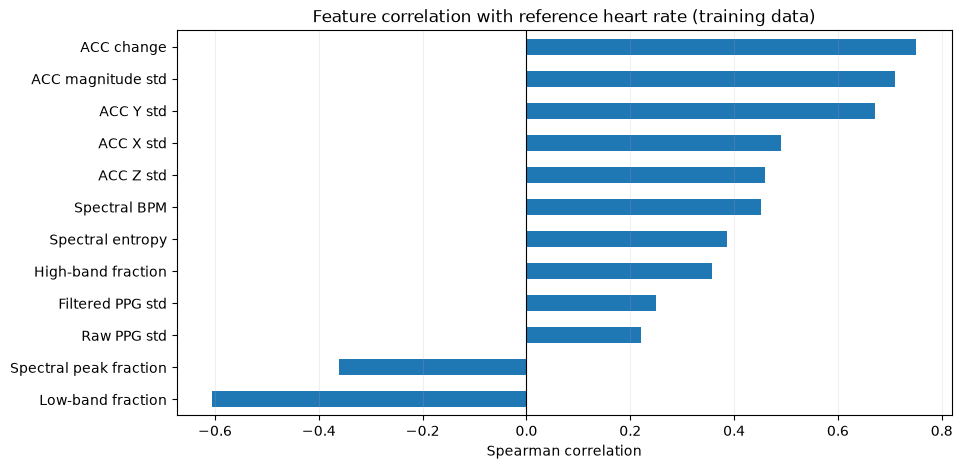

In [11]:
# Correlation between features and reference heart rate
correlations = train[feature_cols + [target]].corr(
    method="spearman"
)[target].drop(target)

correlations = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

display(correlations.to_frame("Correlation").round(3))

plt.figure(figsize=(10, 5))
correlations.sort_values().plot(kind="barh")

plt.title("Feature correlation with reference heart rate (training data)")
plt.xlabel("Spearman correlation")
plt.axvline(0, color="black", linewidth=0.8)
plt.grid(axis="x", alpha=0.2)
plt.show()

## 11. Compare model and feature choices on validation data

Try two modest gradient-boosting configurations and five feature sets. The *ACC-only* result is a diagnostic: it can expose activity-based shortcuts, but the final model must retain **some PPG-derived features**.

The reduced feature set reflects earlier exploratory ablation choices. We select based on **validation MAE only**, leaving the test set untouched. All comparison models have the same training procedure.

In [12]:
configs = [
    {"max_iter": 150, "max_leaf_nodes": 15},
    {"max_iter": 250, "max_leaf_nodes": 31}
]

ppg_features = [f for f in feature_cols if not f.startswith("ACC")]
acc_features = [f for f in feature_cols if f.startswith("ACC")]

feature_sets = {
    "All features": feature_cols,
    "Without ACC change": [f for f in feature_cols if f != "ACC change"],
    "Reduced features": [f for f in feature_cols if f not in
                         ["ACC change", "High-band fraction", "Spectral entropy"]],
    "PPG only": ppg_features,
    "ACC only (diagnostic)": acc_features
}

validation_rows = []
trained_candidates = {}

for name, cols in feature_sets.items():
    for config_number, config in enumerate(configs):
        candidate = HistGradientBoostingRegressor(
            learning_rate=0.05, l2_regularization=1.0,
            early_stopping=False, random_state=42, **config
        )
        candidate.fit(train[cols], train[target])
        predictions = candidate.predict(val[cols])
        mae = mean_absolute_error(val[target], predictions)

        validation_rows.append({
            "Feature set": name, "Config": config_number + 1,
            "Features": len(cols), "Validation MAE": mae
        })
        trained_candidates[(name, config_number + 1)] = candidate

validation_results = pd.DataFrame(validation_rows)
display(validation_results.sort_values("Validation MAE").round(3))

baseline_val_mae = mean_absolute_error(val[target], val["Spectral BPM"])
print(f"Spectral baseline validation MAE: {baseline_val_mae:.3f} BPM")

,Feature set,Config,Features,Validation MAE
3,Without ACC change,2,11,6.152
5,Reduced features,2,9,6.178
4,Reduced features,1,9,6.244
2,Without ACC change,1,11,6.251
1,All features,2,12,6.412
0,All features,1,12,6.572
6,PPG only,1,7,8.247
7,PPG only,2,7,8.566
9,ACC only (diagnostic),2,5,9.839
8,ACC only (diagnostic),1,5,9.881


Spectral baseline validation MAE: 11.521 BPM


### Choose the winning configuration

Select the best validation score among models that use PPG. The stored model is also used for the feature-importance check below, avoiding another training pass.

In [13]:
eligible = validation_results[
    validation_results["Feature set"] != "ACC only (diagnostic)"
]
best = eligible.sort_values("Validation MAE").iloc[0]

best_name = best["Feature set"]
best_config = configs[int(best["Config"]) - 1]
selected_features = feature_sets[best_name]
validation_model = trained_candidates[(best_name, int(best["Config"]))]

print(f"Selected: {best_name} | Config {int(best['Config'])}")
print(f"Validation MAE: {best['Validation MAE']:.3f} BPM")
print(f"Selected features ({len(selected_features)}): {', '.join(selected_features)}")
print("Excluded features:", sorted(set(feature_cols) - set(selected_features)))

Selected: Without ACC change | Config 2
Validation MAE: 6.152 BPM
Selected features (11): Spectral BPM, Spectral peak fraction, Spectral entropy, Low-band fraction, High-band fraction, Filtered PPG std, Raw PPG std, ACC magnitude std, ACC X std, ACC Y std, ACC Z std
Excluded features: ['ACC change']


## 12. Which selected features does the model rely on?

Permutation importance measures the increase in **validation** MAE after shuffling a feature in the trained validation model. It shows *reliance*, not causation; correlated features may mask one another.

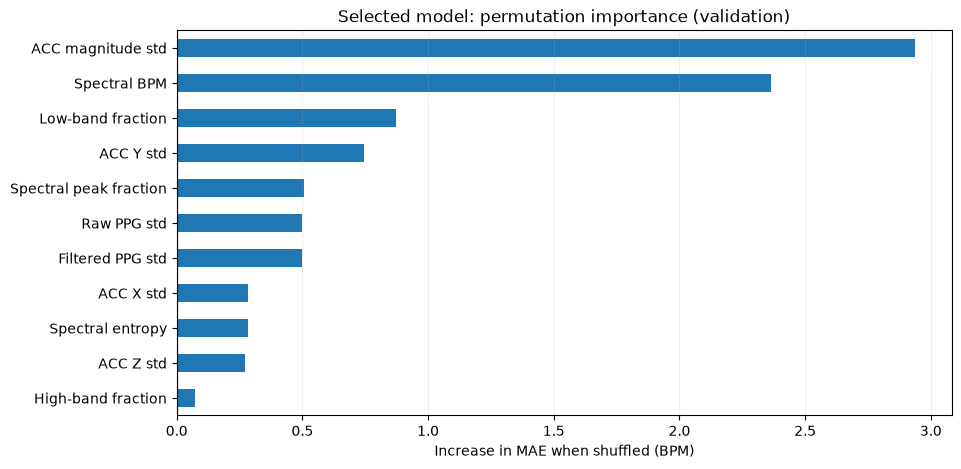

In [14]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    validation_model, val[selected_features], val[target],
    scoring="neg_mean_absolute_error", n_repeats=5, random_state=42
)

importance_scores = pd.Series(
    importance.importances_mean, index=selected_features
).sort_values()

plt.figure(figsize=(10, 5))
importance_scores.plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Selected model: permutation importance (validation)")
plt.xlabel("Increase in MAE when shuffled (BPM)")
plt.grid(axis="x", alpha=0.2)
plt.show()

## 13. Fit once on train + validation; evaluate once on test

After fixing the feature set and hyperparameters, refit on the combined earlier data. Use the untouched later test period **only** to report final performance against the filtered spectral baseline.

In [15]:
final_train = pd.concat([train, val], ignore_index=True)

model = HistGradientBoostingRegressor(
    learning_rate=0.05, l2_regularization=1.0,
    early_stopping=False, random_state=42, **best_config
)
model.fit(final_train[selected_features], final_train[target])

test = test.copy()
test["ML estimate (BPM)"] = model.predict(test[selected_features])

scores = []
for subject in [*SUBJECTS, "Overall"]:
    df = test if subject == "Overall" else test[test["Subject"] == subject]
    for method, column in [
        ("Spectral baseline", "Spectral BPM"),
        ("Gradient boosting", "ML estimate (BPM)")
    ]:
        scores.append({
            "Subject": subject, "Method": method,
            "MAE (BPM)": mean_absolute_error(df[target], df[column]),
            "RMSE (BPM)": np.sqrt(mean_squared_error(df[target], df[column]))
        })

display(pd.DataFrame(scores).round(2))

,Subject,Method,MAE (BPM),RMSE (BPM)
0,S1,Spectral baseline,6.83,13.26
1,S1,Gradient boosting,4.45,6.24
2,S4,Spectral baseline,12.92,20.13
3,S4,Gradient boosting,5.34,7.06
4,Overall,Spectral baseline,9.86,17.03
5,Overall,Gradient boosting,4.89,6.66


## 14. Inspect held-out test predictions

Show the first `GRAPH_DURATION` seconds of each subject's **test portion**. `GRAPH_START` isn't used here because it may point to an interval that the model trained on.

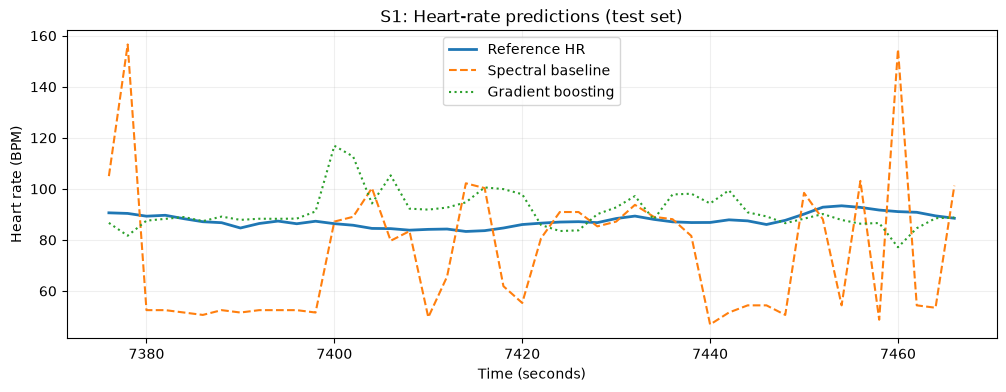

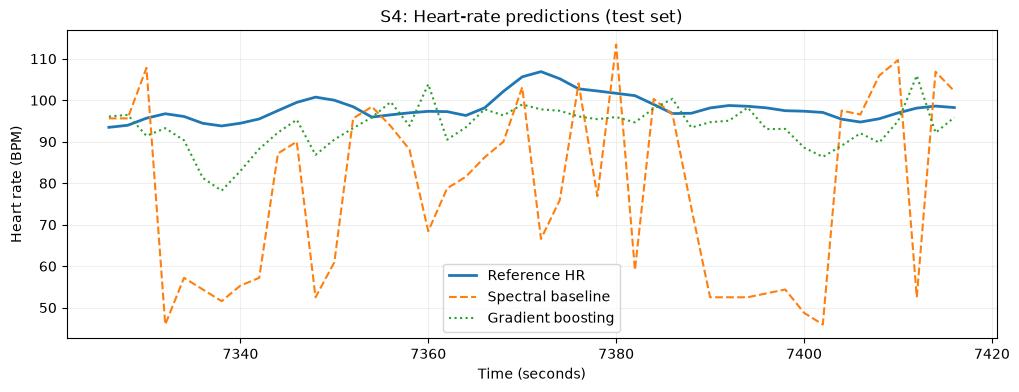

In [16]:
for subject in SUBJECTS:
    df = test[test["Subject"] == subject]

    # Start from the first test window
    start = df["Time (s)"].min()
    df = df[df["Time (s)"] <= start + GRAPH_DURATION]

    plt.figure(figsize=(12, 4))

    plt.plot(df["Time (s)"], df[target],
             label="Reference HR", linewidth=2)

    plt.plot(df["Time (s)"], df["Spectral BPM"],
             label="Spectral baseline", linestyle="--")

    plt.plot(df["Time (s)"], df["ML estimate (BPM)"],
             label="Gradient boosting", linestyle=":")

    plt.title(f"{subject}: Heart-rate predictions (test set)")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Heart rate (BPM)")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

## 15. Check whether error grows with wrist movement

Plot movement variability against absolute error on the **held-out test set**. An association would not prove that motion caused the errors.

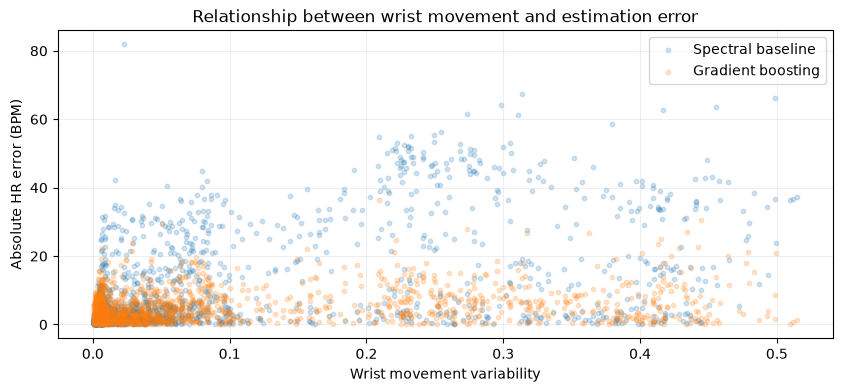

In [17]:
test["Baseline error"] = abs(test["Spectral BPM"] - test[target])
test["ML error"] = abs(test["ML estimate (BPM)"] - test[target])

plt.figure(figsize=(10, 4))

plt.scatter(
    test["ACC magnitude std"],
    test["Baseline error"],
    alpha=0.2, s=10,
    label="Spectral baseline"
)

plt.scatter(
    test["ACC magnitude std"],
    test["ML error"],
    alpha=0.2, s=10,
    label="Gradient boosting"
)

plt.xlabel("Wrist movement variability")
plt.ylabel("Absolute HR error (BPM)")
plt.title("Relationship between wrist movement and estimation error")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# kol ma nemshy ymeen (y3ny wrist movement aktr) el error yzeed
# w dh el e7na kona mot5yleeno f3ln
# bs el gradient a7sn mn el spectral, w b nseba kbeera bye3raf y-handle el 7agat
# w dh manteky, l2n el gradient boosting byesta3mel el accelerometer features, el tany kan byesta3mel
# el ppg frequencies bs


,Windows,Baseline_MAE,ML_MAE
Movement level,,,
Low,609,2.37,3.95
Medium,609,6.55,3.97
High,610,20.65,6.76


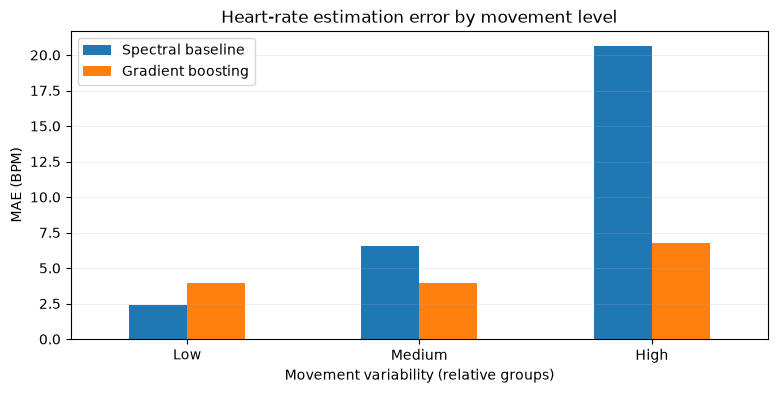

In [18]:
movement_analysis = test.copy()

movement_analysis["Movement level"] = pd.qcut(
    movement_analysis["ACC magnitude std"],
    q=3,
    labels=["Low", "Medium", "High"]
)

summary = movement_analysis.groupby(
    "Movement level",
    observed=True
).agg(
    Windows=("Baseline error", "size"),
    Baseline_MAE=("Baseline error", "mean"),
    ML_MAE=("ML error", "mean")
)

display(summary.round(2))

summary[["Baseline_MAE", "ML_MAE"]].plot(
    kind="bar", figsize=(9, 4)
)

plt.title("Heart-rate estimation error by movement level")
plt.xlabel("Movement variability (relative groups)")
plt.ylabel("MAE (BPM)")
plt.xticks(rotation=0)
plt.legend(["Spectral baseline", "Gradient boosting"])
plt.grid(axis="y", alpha=0.2)
plt.show()

## 16. Takeaways and limitations

Fill these in **after running on real PPG-DaLiA recordings**:

- **Spectral baseline:** What were its full-recording errors? Did filtering help consistently?
- **Feature experiments:** Which feature set/configuration won on validation? Did ACC-only do surprisingly well?
- **Unseen test periods:** Did the ML model improve test MAE/RMSE compared with the spectral baseline?
- **Failure cases:** Which periods were difficult, and did those periods show strong wrist motion?
- **Limitations:** Overlapping windows; offline non-causal filtering; short 8-second frequency resolution; chronological split tests later periods of known subjects, not new people; physical activity can act as a proxy for heart rate.
- **Next experiment:** Hold out an entire subject, train on the remaining participants, and test whether improvements generalize.

**Important:** These are signal-processing and machine-learning estimates, **not medical diagnoses**. The reference is used for training labels and evaluation only; it is never a predictive input feature.